# 02 - Preprocessing & Data Augmentation | VNDCash
**Dự án**: XÂY DỰNG ỨNG DỤNG NHẬN DIỆN TIỀN GIẤY VIỆT NAM BẰNG CNN  
**Thành viên phụ trách**: Thành viên A (Data Engineering & Data Pipeline)  

Notebook này trực quan hóa pipeline tiền xử lý (Preprocessing), chuẩn hóa kích thước, và minh họa các phép biến đổi tăng cường dữ liệu (Data Augmentation) áp dụng riêng cho tập Train.

In [1]:
import sys
from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocessing import get_eval_transforms, preprocess_image, denormalize_tensor
from src.data.augmentation import get_train_transforms
from src.data.dataset import get_dataloaders
from src.utils.paths import SPLITS_CSV

## 1. Trực quan hóa ảnh gốc và ảnh sau khi tiền xử lý (Resize 224x224 & Normalize)

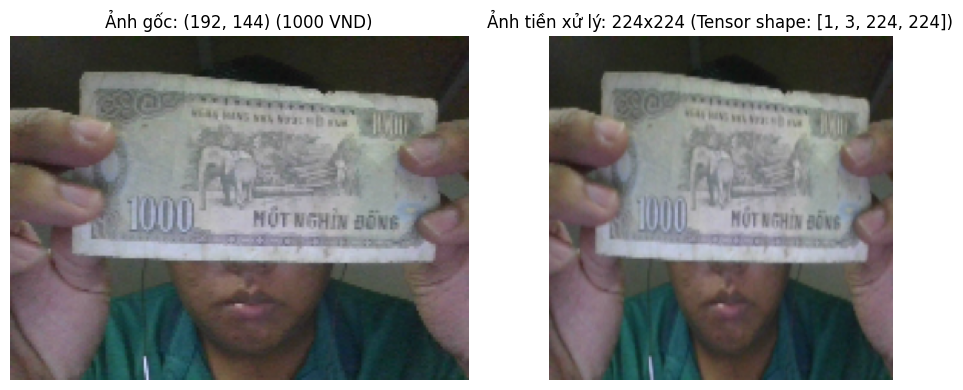

In [2]:
import pandas as pd
df = pd.read_csv(SPLITS_CSV)
sample_row = df.iloc[0]
sample_path = PROJECT_ROOT / sample_row['rel_path']

orig_img = Image.open(sample_path)
preprocessed_tensor = preprocess_image(orig_img, image_size=(224, 224))
denorm_img = denormalize_tensor(preprocessed_tensor)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(orig_img)
axes[0].set_title(f"Ảnh gốc: {orig_img.size} ({sample_row['denomination']} VND)", fontsize=12)
axes[0].axis('off')

axes[1].imshow(denorm_img)
axes[1].set_title(f"Ảnh tiền xử lý: 224x224 (Tensor shape: {list(preprocessed_tensor.shape)})", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 2. Trực quan hóa Data Augmentation (Chỉ áp dụng cho tập Train)
Các biến đổi mô phỏng thực tế: lật ngang, xoay góc nghiêng, đổi ánh sáng/độ tương phản, co giãn phối cảnh và làm mờ nét.

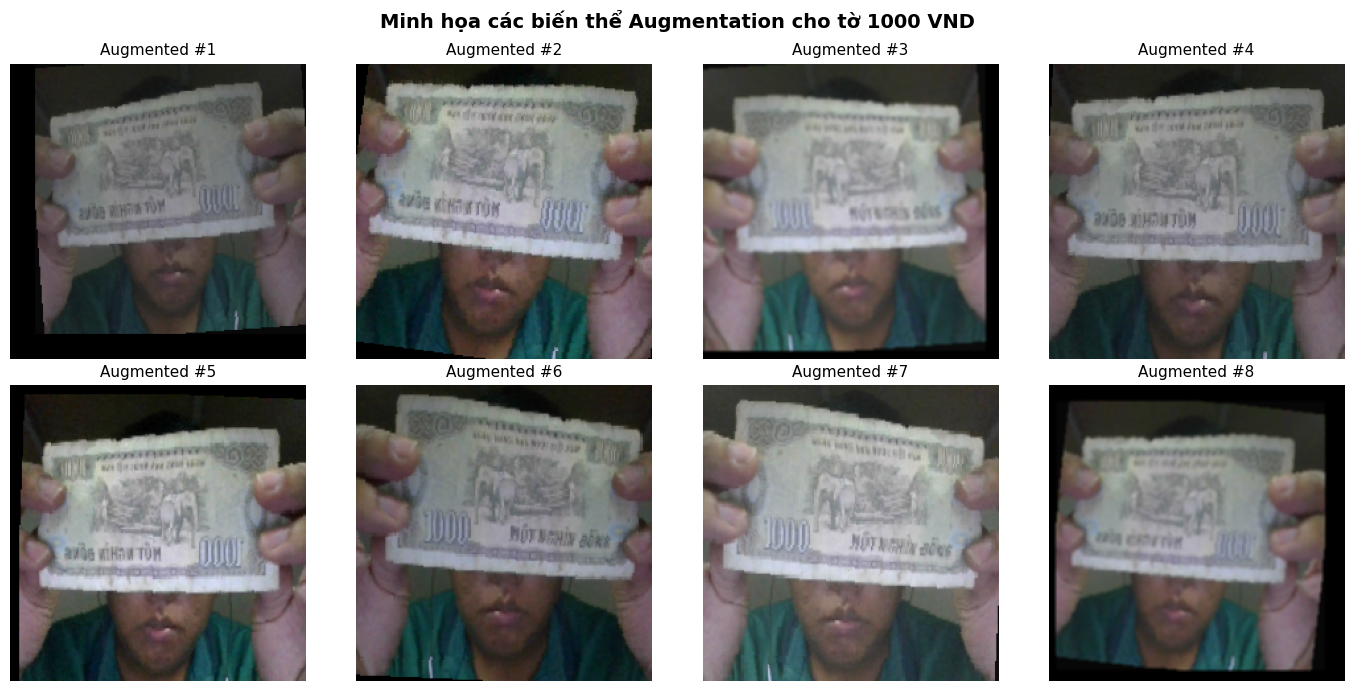

In [3]:
train_transform = get_train_transforms(image_size=(224, 224))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    aug_tensor = train_transform(orig_img)
    aug_img = denormalize_tensor(aug_tensor)
    ax.imshow(aug_img)
    ax.set_title(f"Augmented #{i+1}", fontsize=11)
    ax.axis('off')

plt.suptitle(f"Minh họa các biến thể Augmentation cho tờ {sample_row['denomination']} VND", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Kiểm thử nạp Batch từ DataLoaders (Train, Val, Test)

In [4]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=8, num_workers=0)
print(f"Số batch Train : {len(train_loader)} (mỗi batch 8 ảnh)")
print(f"Số batch Val   : {len(val_loader)}")
print(f"Số batch Test  : {len(test_loader)}")

batch_images, batch_labels = next(iter(train_loader))
print(f"\nShape batch ảnh : {batch_images.shape}")
print(f"Labels của batch: {batch_labels.tolist()}")

Số batch Train : 171 (mỗi batch 8 ảnh)
Số batch Val   : 38
Số batch Test  : 38

Shape batch ảnh : torch.Size([8, 3, 224, 224])
Labels của batch: [1, 0, 8, 2, 3, 7, 7, 0]


c:\Users\ndt06\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
